# Audit summary numbers

This notebook recomputes the summary numbers and the defect chart of the benchmark audit. It reads `audit_log.csv` (one row per task and check), `results/static_scan.csv` (the no-op scan of all 50 airline tasks) and `sample.json` (the 20 sampled task ids and the pinned benchmark commit). All logic lives in `make_summary.py`; this notebook only calls it. A task counts as defective when it has at least one confirmed defect of severity high or medium. Every share carries a 95% Wilson interval.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import make_summary

make_summary.selftest()
md = make_summary.run(ROOT)

selftest passed


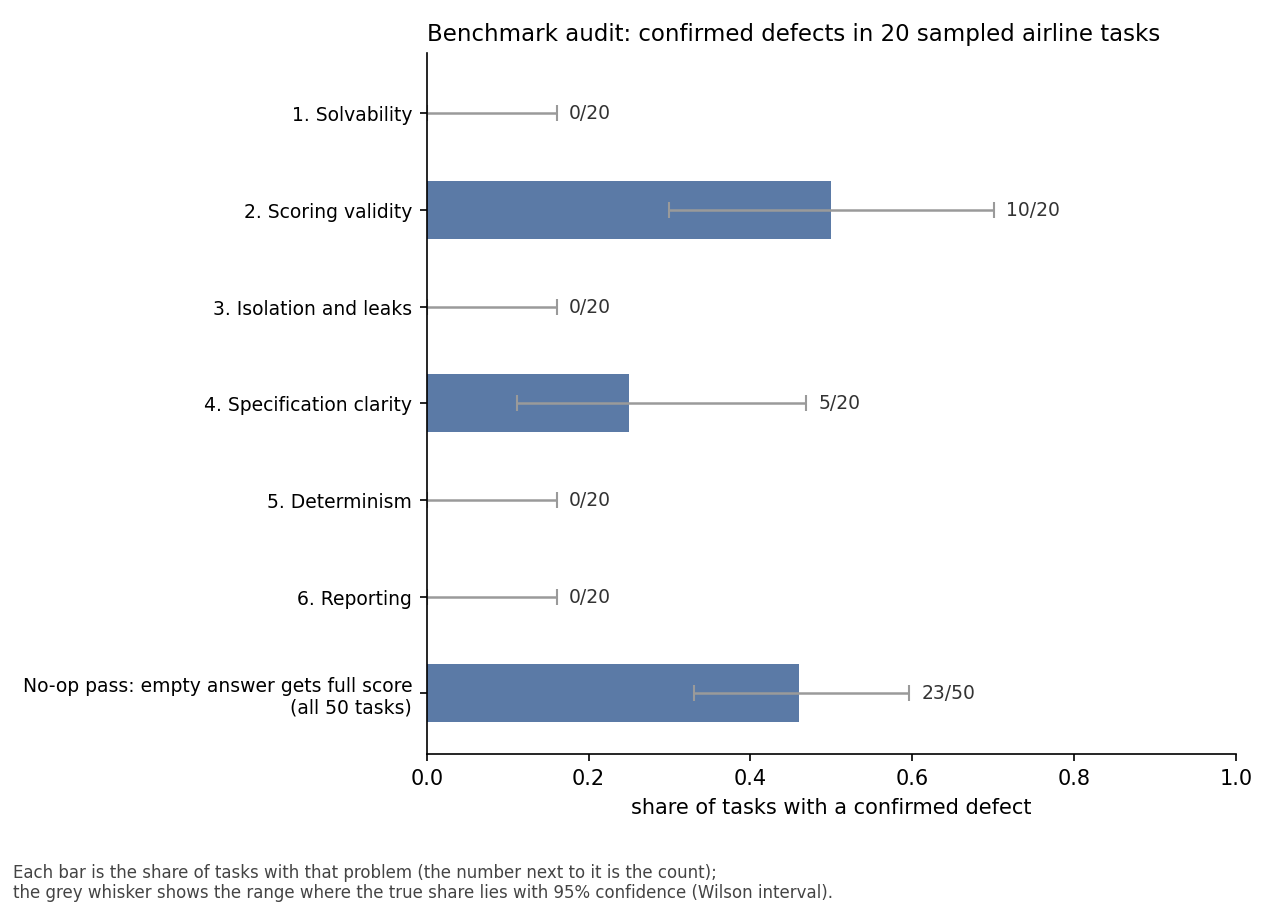

In [2]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'fig_defects.png')))

In [3]:
print((ROOT / 'summary_numbers.md').read_text(encoding='utf-8'))

# Summary numbers

bench_commit: `989d3285ae669e49503324bdb9981bf14fccedeb`

Intervals: 95% Wilson.

Table 1. Headline shares

| quantity | share |
|---|---|
| defective tasks, sampled tasks | 13/20 = 0.650 [0.433, 0.819] |
| defective tasks, sampled tasks, excluding the documented no-op class (checks 2a, 2b) | 11/20 = 0.550 [0.342, 0.742] |
| defective tasks, sampled tasks, excluding every defect that derives from the no-op design (checks 2a, 2b, and 2k rows on tasks with noop_pass = 1 in results/static_scan.csv) | 6/20 = 0.300 [0.145, 0.519] |
| no-op pass, all airline tasks | 23/50 = 0.460 [0.330, 0.596] |
| no-op pass, sampled tasks | 7/20 = 0.350 [0.181, 0.567] |
| medium/high defect rows with skeptic_ok empty (whole file, incl. task_id ALL) | 0 |

Table 2. Sampled tasks with ≥1 confirmed defect (high/medium), by category

| category | share of sampled tasks |
|---|---|
| 1 Solvability | 0/20 = 0.000 [0.000, 0.161] |
| 2 Scoring validity | 10/20 = 0.500 [0.299, 0.701] |
| 3 Isolat